# 01 · Exploración de datos (EDA) — 3B Geo-Expansion

**Fase 1 del proyecto.** Antes de limpiar o modelar, entendemos cada fuente de la capa Bronze.

**Preguntas que debe responder este notebook:**
1. ¿Podemos identificar de forma confiable las tiendas 3B y a su competencia en el DENUE?
2. ¿Cuántas **aperturas reales 2021→2026** hay para el backtest? (la pieza central del proyecto)
3. ¿Las llaves de unión censo ↔ mapa ↔ CONEVAL funcionan?
4. ¿Los proxies de demanda (hogares y perfil socioeconómico) se relacionan con dónde está 3B? (*preferencia revelada*)
5. ¿Qué decisiones debemos tomar en la capa Silver?

> Ejercicio académico con datos públicos; no usa información interna de BBB Foods.

In [1]:
import sys, json
from pathlib import Path
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
from tesela3b import config as cfg

FIG = ROOT / "reports" / "figures"
FIG.mkdir(parents=True, exist_ok=True)

# Paleta (validada para daltonismo, 2-3 series): azul = 3B existente, naranja = apertura, gris = contexto
AZUL, NARANJA, GRIS, GRIS_CLARO, TINTA, TINTA2 = "#2a78d6", "#eb6834", "#9a9893", "#e7e6e2", "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
    "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.edgecolor": GRIS, "axes.labelcolor": TINTA2, "xtick.color": TINTA2, "ytick.color": TINTA2,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": GRIS_CLARO,
    "grid.linewidth": 0.8, "axes.axisbelow": True, "legend.frameon": False,
})
pd.set_option("display.max_columns", 30)
print("Raíz del repo:", ROOT)

Raíz del repo: /home/claude/Proyecto


## 1. DENUE: oferta (3B y competencia)

Leemos solo el **comercio al por menor (SCIAN 46)**, donde están 3B, su competencia y las tienditas. Si existe el extracto comprimido de `data/_tmp/` se usa ese; si no, se lee el CSV completo de Bronze.

In [2]:
COLS = ["id", "clee", "nom_estab", "raz_social", "codigo_act", "nombre_act", "per_ocu",
        "cve_mun", "municipio", "ageb", "manzana", "latitud", "longitud", "fecha_alta"]

def cargar_denue(version: str) -> pd.DataFrame:
    extracto = cfg.DATA / "_tmp" / f"denue46_{version}.csv.gz"
    if extracto.exists():
        return pd.read_csv(extracto, dtype=str)
    ruta = cfg.BRONZE / "denue" / version / "conjunto_de_datos" / "denue_inegi_09_.csv"
    df = pd.read_csv(ruta, encoding="latin-1", dtype=str, usecols=COLS)
    return df[df["codigo_act"].str.startswith("46")].reset_index(drop=True)

denue = {v: cargar_denue(v) for v in ["2021_11", "2026_05"]}
pd.DataFrame({v: {"establecimientos comercio al por menor": len(d),
                  "tiendas de abarrotes (461110)": (d.codigo_act == "461110").sum(),
                  "minisupers (462112)": (d.codigo_act == "462112").sum(),
                  "supermercados (462111)": (d.codigo_act == "462111").sum(),
                  "coordenadas nulas": d.latitud.isna().sum()} for v, d in denue.items()})

,2021_11,2026_05
establecimientos comercio al por menor,203204,212251
tiendas de abarrotes (461110),37993,38996
minisupers (462112),3134,3065
supermercados (462111),501,313
coordenadas nulas,0,0


### 1.1 Identificación de tiendas 3B

Buscamos el patrón de `config.PATRONES_CADENAS["3B"]` en **nombre + razón social**, nos quedamos con códigos de tienda (`config.SCIAN_TIENDAS`) y excluimos registros que no son tiendas (CEDIS, oficinas) o que son otra marca con razón social de 3B.

In [3]:
EXCLUIR = r"CEDIS|CENTRO DE DISTRIBUCION|OFICINAS|CIRCULO K|SUPER YEMA"

def texto(df):
    return (df.nom_estab.fillna("") + " | " + df.raz_social.fillna("")).str.upper()

def identificar_3b(df):
    t = texto(df)
    candidato = t.str.contains(cfg.PATRONES_CADENAS["3B"], regex=True)
    excluido = t.str.contains(EXCLUIR, regex=True) | ~df.codigo_act.isin(cfg.SCIAN_TIENDAS)
    return candidato, candidato & ~excluido

resumen = {}
for v, d in denue.items():
    cand, ok = identificar_3b(d)
    resumen[v] = {"coincidencias del patrón": cand.sum(), "excluidas (no tienda / otra marca)": (cand & ~ok).sum(),
                  "tiendas 3B (antes de deduplicar)": ok.sum()}
    print(f"\n{v} · registros excluidos:")
    print(d[cand & ~ok][["nom_estab", "raz_social", "codigo_act"]].to_string(index=False))
pd.DataFrame(resumen)


2021_11 · registros excluidos:
                                nom_estab              raz_social codigo_act
CENTRO DE DISTRIBUCION CEDIS  3B SA DE CV TIENDAS TRES B SA DE CV     462112
                                CIRCULO K TIENDAS TRES B SA DE CV     462112
                               TIENDAS 3B             TIENDAS 3B      468212

2026_05 · registros excluidos:
                         nom_estab     raz_social codigo_act
                        SUPER YEMA TIENDAS TRES B     462111
TIENDAS TRES B OFICINAS EJECUTIVAS TIENDAS TRES B     462112


,2021_11,2026_05
coincidencias del patrón,151,337
excluidas (no tienda / otra marca),3,2
tiendas 3B (antes de deduplicar),148,335


### 1.2 Duplicados: la misma tienda registrada dos veces

Si dos registros 3B están a menos de 50 m, casi siempre son la misma tienda (misma manzana, distinta fecha de alta). 3B no abre dos tiendas en la misma cuadra. Regla: **agrupar registros a < 50 m y conservar el de fecha de alta más antigua.**

In [4]:
def a_puntos(df):
    g = gpd.GeoDataFrame(df, geometry=gpd.points_from_xy(df.longitud.astype(float), df.latitud.astype(float)), crs=cfg.CRS_WEB)
    return g.to_crs(cfg.CRS_METRIC)  # metros, para medir distancias

def deduplicar(g, umbral_m=50):
    g = g.sort_values("fecha_alta").reset_index(drop=True)
    buf = g.buffer(umbral_m / 2)
    grupos = gpd.GeoDataFrame(geometry=[buf.union_all()], crs=g.crs).explode(index_parts=False).reset_index(drop=True)
    g["grupo"] = gpd.sjoin(g, grupos, predicate="within", how="left")["index_right"].values
    return g.drop_duplicates("grupo", keep="first").drop(columns="grupo")

tiendas = {}
for v, d in denue.items():
    _, ok = identificar_3b(d)
    g = a_puntos(d[ok].copy())
    tiendas[v] = deduplicar(g)
    print(f"{v}: {len(g)} registros -> {len(tiendas[v])} tiendas únicas ({len(g) - len(tiendas[v])} duplicados)")

2021_11: 148 registros -> 143 tiendas únicas (5 duplicados)
2026_05: 335 registros -> 305 tiendas únicas (30 duplicados)


### 1.3 Aperturas 2021 → 2026: la etiqueta del backtest

Una tienda de 2026 es **apertura** si no había una 3B a menos de 100 m en noviembre de 2021.

In [5]:
t21, t26 = tiendas["2021_11"], tiendas["2026_05"]
cerca = gpd.sjoin_nearest(t26[["id", "fecha_alta", "municipio", "geometry"]],
                          t21[["geometry"]], distance_col="dist_2021_m")
cerca = cerca[~cerca.index.duplicated()]
t26 = t26.assign(dist_2021_m=cerca["dist_2021_m"], apertura=cerca["dist_2021_m"] >= 100)

sens = pd.Series({f"umbral {u} m": int((cerca.dist_2021_m >= u).sum()) for u in [50, 100, 200]}, name="aperturas")
cierres = gpd.sjoin_nearest(t21[["geometry"]], t26[["geometry"]], distance_col="d")
cierres = cierres[~cierres.index.duplicated()]
print(f"Tiendas 3B únicas: 2021 = {len(t21)}, 2026 = {len(t26)}")
print(f"Aperturas (umbral 100 m): {t26.apertura.sum()}  |  tiendas 2021 sin equivalente en 2026: {(cierres.d >= 100).sum()}")
display(sens.to_frame())
t26[t26.apertura].fecha_alta.value_counts().sort_index().to_frame("aperturas por fecha de alta en el DENUE")

Tiendas 3B únicas: 2021 = 143, 2026 = 305
Aperturas (umbral 100 m): 169  |  tiendas 2021 sin equivalente en 2026: 8


,aperturas
umbral 50 m,181
umbral 100 m,169
umbral 200 m,163


,aperturas por fecha de alta en el DENUE
fecha_alta,
2016-01,3
2019-11,3
2023-11,77
2024-05,49
2024-11,4
2026-04,33


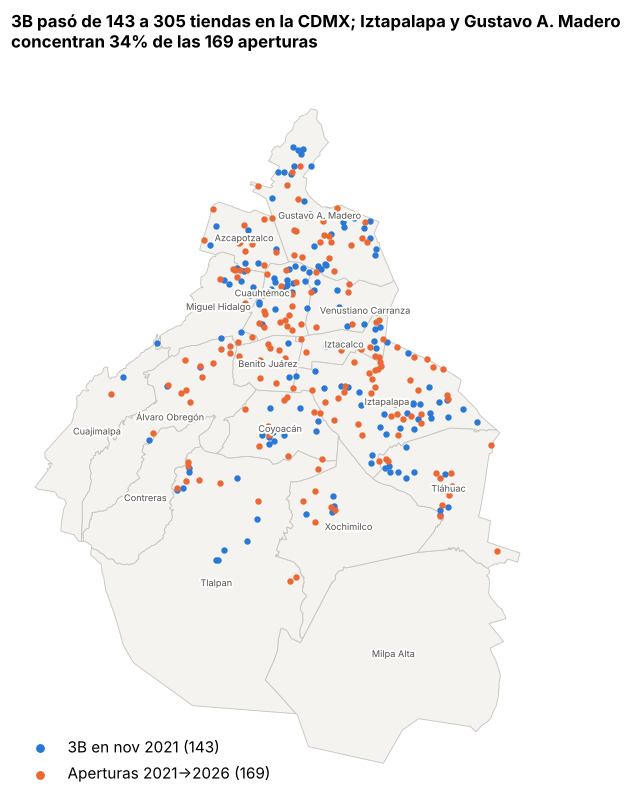

In [6]:
mun = gpd.read_file(cfg.BRONZE / "marco_geo" / "conjunto_de_datos" / "09mun.shp").to_crs(cfg.CRS_METRIC)

fig, ax = plt.subplots(figsize=(7.5, 8.5))
mun.plot(ax=ax, color="#f4f3f0", edgecolor="#c9c7c0", linewidth=0.6)
t21.plot(ax=ax, color=AZUL, markersize=10, label=f"3B en nov 2021 ({len(t21)})", zorder=3)
t26[t26.apertura].plot(ax=ax, color=NARANJA, markersize=10, marker="o", label=f"Aperturas 2021→2026 ({t26.apertura.sum()})", zorder=4)
import matplotlib.patheffects as pe
AJUSTE = {"Cuauhtémoc": (-1800, 900), "Venustiano Carranza": (1800, -600)}  # metros, evita que se encimen
for _, r in mun.iterrows():
    dx, dy = AJUSTE.get(r.NOMGEO, (0, 0))
    p = r.geometry.centroid
    ax.annotate(r.NOMGEO.replace(" de Morelos", "").replace("La Magdalena ", ""), (p.x + dx, p.y + dy), fontsize=6, color=TINTA2,
                ha="center", va="center", path_effects=[pe.withStroke(linewidth=2.5, foreground="white")], zorder=5)
ax.set_axis_off()
top2 = t26[t26.apertura].municipio.value_counts().head(2)
ax.set_title(f"3B pasó de {len(t21)} a {len(t26)} tiendas en la CDMX; {top2.index[0]} y {top2.index[1]}\n"
             f"concentran {top2.sum() / t26.apertura.sum():.0%} de las {t26.apertura.sum()} aperturas", fontsize=11)
ax.legend(loc="lower left", markerscale=1.5)
fig.savefig(FIG / "01_mapa_3b_2021_aperturas.png")
plt.show()

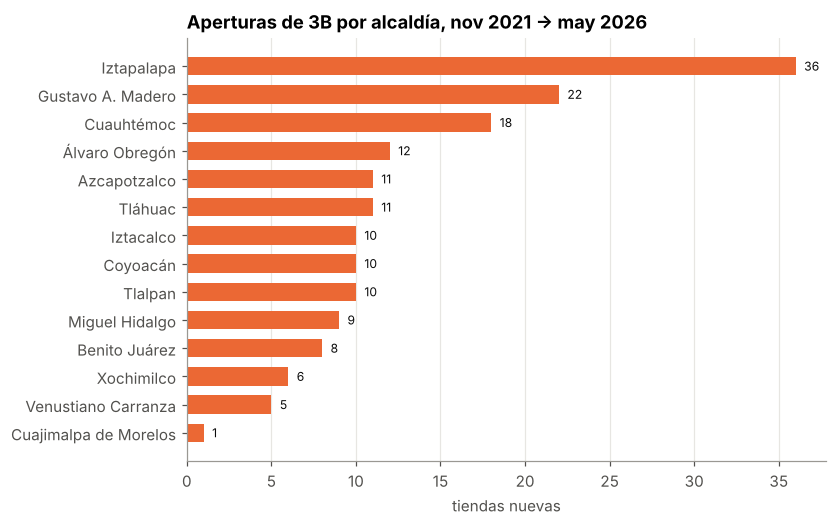

,tiendas_2026,aperturas
municipio,,
Iztapalapa,63,36
Gustavo A. Madero,48,22
Cuauhtémoc,35,18
Álvaro Obregón,13,12
Azcapotzalco,17,11
Tláhuac,21,11
Coyoacán,22,10
Tlalpan,17,10
Iztacalco,15,10


In [7]:
por_alc = (t26.groupby("municipio").agg(tiendas_2026=("id", "size"), aperturas=("apertura", "sum"))
              .sort_values("aperturas"))
fig, ax = plt.subplots(figsize=(7.5, 5))
ax.barh(por_alc.index, por_alc.aperturas, color=NARANJA, height=0.65)
for i, v in enumerate(por_alc.aperturas):
    ax.text(v + 0.5, i, str(v), va="center", fontsize=8, color=TINTA)
ax.set_title("Aperturas de 3B por alcaldía, nov 2021 → may 2026")
ax.set_xlabel("tiendas nuevas"); ax.grid(axis="y", visible=False)
fig.savefig(FIG / "01_aperturas_por_alcaldia.png")
plt.show()
por_alc.sort_values("aperturas", ascending=False)

### 1.4 Competencia

Hallazgo: **Bodega Aurrera casi no aparece por su nombre.** Walmart registra sus tiendas con la razón social *Nueva Wal Mart de México* y nombres internos ("BA EXPRESS …", "BAE …", "BODEGA …", "SUPERAMA …", "SAMS …"). Hay que clasificar los formatos de Walmart por prefijo del nombre.

In [8]:
def clasificar_competencia(df):
    t, nom = texto(df), df.nom_estab.fillna("").str.upper()
    walmart = df.raz_social.fillna("").str.upper().str.contains(r"WAL ?MART")
    reglas = {
        "3B": identificar_3b(df)[1],
        "Bodega Aurrera": (walmart & nom.str.contains(r"^(?:BODEGA|BA\b|BAE\b|BOA\b|MI BODEGA)|AURRERA")) | t.str.contains("AURRERA"),
        "Walmart otros formatos": walmart & nom.str.contains(r"SUPERAMA|SUPERCENTER|^SC\b|SAMS|SAM S|WALMART"),
        "Neto": t.str.contains(r"\bNETO\b") & df.codigo_act.isin(cfg.SCIAN_TIENDAS) & ~t.str.contains("DON NETO|ZAPATER"),
        "OXXO": t.str.contains(r"\bOXXO\b") & ~t.str.contains("CEDIS"),
        "7-Eleven": t.str.contains(r"7 ?- ?ELEVEN"),
        "Circle K": t.str.contains(r"CIRCLE K|CIRCULO K") & ~identificar_3b(df)[0],
        "Abarrotes (461110)": df.codigo_act.eq("461110"),
    }
    return pd.Series({k: int(v.sum()) for k, v in reglas.items()})

comp = pd.DataFrame({v: clasificar_competencia(d) for v, d in denue.items()})
comp.loc["3B"] = [len(t21), len(t26)]  # ya deduplicado
comp["cambio %"] = ((comp["2026_05"] / comp["2021_11"] - 1) * 100).round(0)
comp

,2021_11,2026_05,cambio %
3B,143,305,113.0
Bodega Aurrera,189,200,6.0
Walmart otros formatos,95,91,-4.0
Neto,29,238,721.0
OXXO,1271,1494,18.0
7-Eleven,372,342,-8.0
Circle K,114,201,76.0
Abarrotes (461110),37993,38996,3.0


**Cuidado al leer esta tabla:** el salto de Neto (+700%) **no es crecimiento real**. En el DENUE 2021 el INEGI clasificó la mayoría de las tiendas Neto como *comercio al por mayor* (SCIAN 431110), fuera del sector 46 que filtramos aquí. En Silver, la competencia se buscará en todos los sectores y se reclasificará por nombre. Moraleja: **un cambio en cómo se registra un dato puede parecer un cambio en el negocio.**

## 2. Censo 2020 por AGEB + Marco Geoestadístico: demanda

El CSV mezcla totales de entidad, alcaldía, localidad, AGEB y manzana. Las filas de **AGEB** son `AGEB != "0000"` y `MZA == "000"`.

In [9]:
censo = pd.read_csv(cfg.BRONZE / "censo2020" / "RESAGEBURB_09CSV20.csv", dtype=str, encoding="utf-8-sig")
ageb = censo[(censo.AGEB != "0000") & (censo.MZA == "000")].copy()
ageb["CVEGEO"] = ageb.ENTIDAD + ageb.MUN + ageb.LOC + ageb.AGEB
VARS = ["POBTOT", "TOTHOG", "TVIVPARHAB", "VPH_AUTOM", "VPH_REFRI", "VPH_LAVAD", "VPH_PC", "VPH_INTER", "GRAPROES", "PROM_OCUP"]
for v in VARS:
    ageb[v] = pd.to_numeric(ageb[v].replace({"*": None, "N/D": None}), errors="coerce")

print(f"Filas totales: {len(censo):,}  |  AGEB urbanas: {len(ageb):,}  |  población en AGEB: {ageb.POBTOT.sum():,.0f}  |  hogares: {ageb.TOTHOG.sum():,.0f}")
ageb[VARS].isna().sum().to_frame("valores confidenciales (*)").T

Filas totales: 68,941  |  AGEB urbanas: 2,433  |  población en AGEB: 9,145,632  |  hogares: 2,739,619


,POBTOT,TOTHOG,TVIVPARHAB,VPH_AUTOM,VPH_REFRI,VPH_LAVAD,VPH_PC,VPH_INTER,GRAPROES,PROM_OCUP
valores confidenciales (*),0,11,11,20,12,17,16,15,10,10


In [10]:
poly = gpd.read_file(cfg.BRONZE / "marco_geo" / "conjunto_de_datos" / "09a.shp")
print("CRS del Marco Geoestadístico:", poly.crs.name, "(Lambert de INEGI, ITRF2008; equivalente a EPSG:6372)")
poly = poly.to_crs(cfg.CRS_METRIC)
poly["area_km2"] = poly.area / 1e6

union = pd.Series({
    "AGEB del censo con polígono": ageb.CVEGEO.isin(poly.CVEGEO).mean(),
    "polígonos con datos del censo": poly.CVEGEO.isin(ageb.CVEGEO).mean(),
    "población cubierta": ageb.loc[ageb.CVEGEO.isin(poly.CVEGEO), "POBTOT"].sum() / ageb.POBTOT.sum(),
}).map("{:.2%}".format)
print(ageb[~ageb.CVEGEO.isin(poly.CVEGEO)][["CVEGEO", "NOM_MUN", "POBTOT"]].to_string(index=False))
union.to_frame("cobertura de la unión por CVEGEO")

CRS del Marco Geoestadístico: MEXICO_ITRF_2008_LCC (Lambert de INEGI, ITRF2008; equivalente a EPSG:6372)


       CVEGEO NOM_MUN  POBTOT
0901101101107 Tláhuac    3050
0901201351227 Tlalpan    4058


,cobertura de la unión por CVEGEO
AGEB del censo con polígono,99.92%
polígonos con datos del censo,100.00%
población cubierta,99.92%


## 3. CONEVAL: Grado de Rezago Social por AGEB

El Excel trae encabezados en varias filas; los datos empiezan en la fila 7 y la columna 8 (*Clave de la AGEB*) es el `CVEGEO`.

In [11]:
raw = pd.read_excel(cfg.BRONZE / "coneval" / "GRS_AGEB_urbana_2020.xlsx", header=None, skiprows=6, dtype=str)
grs = raw[raw[0] == cfg.CVE_ENT][[7, 21, 22, 25, 26, 27]].copy()
grs.columns = ["CVEGEO", "pct_sin_lavadora", "pct_sin_refri", "pct_sin_computadora", "pct_sin_internet", "grado_rezago"]
for col in grs.columns[1:5]:
    grs[col] = pd.to_numeric(grs[col], errors="coerce")
ORDEN = ["Muy bajo", "Bajo", "Medio", "Alto", "Muy alto"]
cov = ageb.CVEGEO.isin(grs.CVEGEO)
print(f"AGEB CDMX en CONEVAL: {len(grs):,} | AGEB del censo con GRS: {cov.mean():.1%} | población cubierta: {ageb.POBTOT[cov].sum() / ageb.POBTOT.sum():.1%}")
grs.grado_rezago.value_counts().reindex(ORDEN).to_frame("AGEB")

AGEB CDMX en CONEVAL: 2,410 | AGEB del censo con GRS: 99.1% | población cubierta: 99.8%


,AGEB
grado_rezago,
Muy bajo,948
Bajo,1234
Medio,200
Alto,22
Muy alto,6


**Lectura:** en la CDMX el 90% de las AGEB caen en rezago *Muy bajo* o *Bajo*. El grado resumido **discrimina poco dentro de la ciudad**, así que para el perfil del cliente conviene usar los **indicadores continuos** (porcentaje sin auto, sin lavadora, sin computadora, sin internet) en lugar del grado categórico.

## 4. Preferencia revelada: ¿dónde elige estar 3B?

Si los proxies de demanda sirven, las AGEB donde 3B tiene tiendas deberían tener un perfil distinto. Comparamos las AGEB **con** al menos una tienda 3B en 2026 contra las que **no**, y (vista previa del backtest) las AGEB que **recibieron una apertura** contra las que no tenían 3B en 2021.

In [12]:
demanda = poly.merge(ageb[["CVEGEO", "NOM_MUN"] + VARS], on="CVEGEO", how="inner").merge(grs, on="CVEGEO", how="left")
demanda["hogares_km2"] = demanda.TOTHOG / demanda.area_km2
demanda["pct_sin_auto"] = 100 * (1 - demanda.VPH_AUTOM / demanda.TVIVPARHAB)
demanda = demanda[demanda.TOTHOG > 0].copy()

def marcar(puntos, nombre):
    j = gpd.sjoin(puntos[["geometry"]], demanda[["CVEGEO", "geometry"]], predicate="within")
    demanda[nombre] = demanda.CVEGEO.isin(j.CVEGEO)

marcar(t21, "con_3b_2021"); marcar(t26, "con_3b_2026"); marcar(t26[t26.apertura], "recibio_apertura")

perfil = ["hogares_km2", "pct_sin_auto", "pct_sin_computadora", "GRAPROES"]
etq = {"hogares_km2": "Hogares por km²", "pct_sin_auto": "% viviendas sin auto",
       "pct_sin_computadora": "% viviendas sin computadora", "GRAPROES": "Escolaridad promedio (años)"}
tabla = pd.DataFrame({
    "AGEB con 3B (2026)": demanda[demanda.con_3b_2026][perfil].median(),
    "AGEB sin 3B (2026)": demanda[~demanda.con_3b_2026][perfil].median(),
    "Recibió apertura 2021→26": demanda[demanda.recibio_apertura][perfil].median(),
    "Sin 3B en 2021 y sin apertura": demanda[~demanda.con_3b_2021 & ~demanda.recibio_apertura][perfil].median(),
}).rename(index=etq).round(1)
tabla

,AGEB con 3B (2026),AGEB sin 3B (2026),Recibió apertura 2021→26,Sin 3B en 2021 y sin apertura
Hogares por km²,5486.1,4861.6,5258.6,4859.5
% viviendas sin auto,59.7,55.5,59.0,55.5
% viviendas sin computadora,44.2,40.5,42.6,40.5
Escolaridad promedio (años),11.1,11.4,11.2,11.4


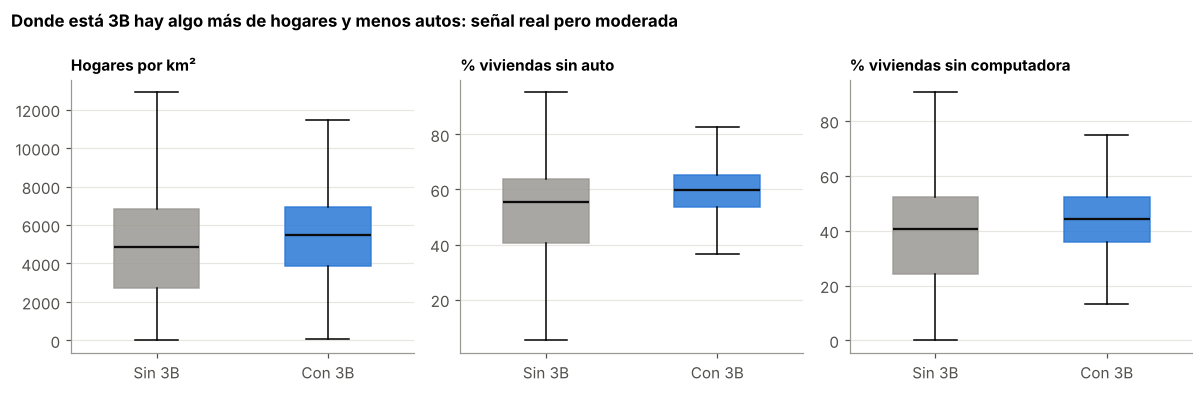

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3.6))
grupos = [("Sin 3B", ~demanda.con_3b_2026, GRIS), ("Con 3B", demanda.con_3b_2026, AZUL)]
for ax, var in zip(axes, ["hogares_km2", "pct_sin_auto", "pct_sin_computadora"]):
    datos = [demanda.loc[m, var].dropna() for _, m, _ in grupos]
    bp = ax.boxplot(datos, tick_labels=[g[0] for g in grupos], widths=0.5, patch_artist=True, showfliers=False,
                    medianprops=dict(color=TINTA, linewidth=1.5))
    for patch, (_, _, col) in zip(bp["boxes"], grupos):
        patch.set_facecolor(col); patch.set_alpha(0.85); patch.set_edgecolor(col)
    ax.set_title(etq[var], fontsize=10); ax.grid(axis="x", visible=False)
fig.suptitle("Donde está 3B hay algo más de hogares y menos autos: señal real pero moderada",
             x=0.01, ha="left", fontweight="bold", fontsize=11)
fig.tight_layout()
fig.savefig(FIG / "01_preferencia_revelada.png")
plt.show()

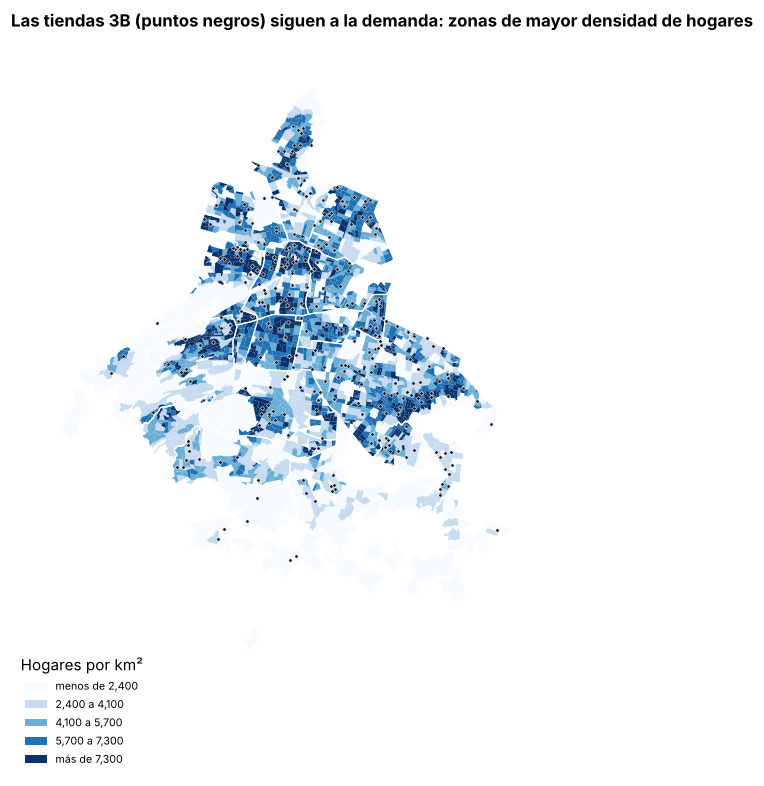

In [14]:
# Mapa de demanda: hogares por km2 (secuencial, un solo tono)
fig, ax = plt.subplots(figsize=(7.5, 8.5))
cortes = demanda.hogares_km2.quantile([0.2, 0.4, 0.6, 0.8]).round(-2).tolist()
etiquetas = [f"menos de {cortes[0]:,.0f}"] + [f"{a:,.0f} a {b:,.0f}" for a, b in zip(cortes[:-1], cortes[1:])] + [f"más de {cortes[-1]:,.0f}"]
demanda.plot(ax=ax, column="hogares_km2", cmap="Blues", scheme="user_defined", classification_kwds={"bins": cortes + [demanda.hogares_km2.max()]},
             linewidth=0, legend=True, legend_kwds={"loc": "lower left", "title": "Hogares por km²", "labels": etiquetas, "fontsize": 7})
mun.boundary.plot(ax=ax, color="white", linewidth=0.8)
t26.plot(ax=ax, color=TINTA, markersize=5, edgecolor="white", linewidth=0.4, zorder=3)
ax.set_axis_off()
ax.set_title("Las tiendas 3B (puntos negros) siguen a la demanda: zonas de mayor densidad de hogares", fontsize=11)
fig.savefig(FIG / "01_mapa_densidad_hogares.png")
plt.show()

## 5. Afluencia del Metro

El archivo trae nombres con acentos mal codificados (`LÃ­nea`): se corrigen recodificando el texto. La serie arranca en 2021, con el Metro aún afectado por la pandemia.

Líneas: 24 variantes en el archivo -> 12 tras normalizar


1,227,915 filas | 2021-01-01 a 2026-09-30 | 166 estaciones | 12 líneas


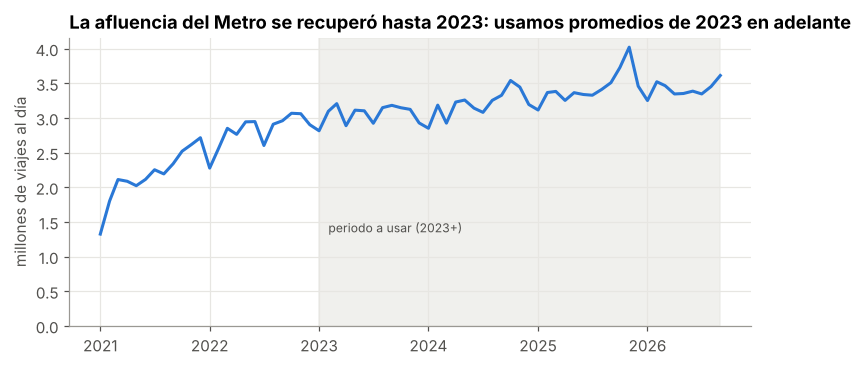

,viajes promedio por día (2023+)
estacion,
Pantitlan,136753.0
Constitucion De 1917,94008.0
Indios Verdes,83962.0
Cuatro Caminos,82516.0
Tacubaya,68247.0
Tasquena,50891.0
Pino Suarez,50827.0
Universidad,50042.0
Buenavista,48166.0


In [15]:
metro = pd.read_csv(cfg.BRONZE / "movilidad" / "afluenciastc_desglosado_09_2026.csv")
import unicodedata
def normalizar(s):
    # 1) corrige la doble codificación (LÃ­nea -> Línea); 2) quita acentos para unificar "Línea"/"Linea"
    s = s.str.encode("latin-1", errors="ignore").str.decode("utf-8", errors="ignore")
    return s.map(lambda x: unicodedata.normalize("NFKD", x).encode("ascii", "ignore").decode()).str.strip().str.title()
n_lineas_crudo = metro.linea.nunique()
metro["linea"], metro["estacion"] = normalizar(metro.linea), normalizar(metro.estacion)
print(f"Líneas: {n_lineas_crudo} variantes en el archivo -> {metro.linea.nunique()} tras normalizar")
metro["fecha"] = pd.to_datetime(metro.fecha)
diaria = metro.groupby("fecha").afluencia.sum()
mensual = diaria.resample("MS").mean() / 1e6
print(f"{len(metro):,} filas | {metro.fecha.min():%Y-%m-%d} a {metro.fecha.max():%Y-%m-%d} | {metro.estacion.nunique()} estaciones | {metro.linea.nunique()} líneas")

fig, ax = plt.subplots(figsize=(8, 3.4))
ax.plot(mensual.index, mensual.values, color=AZUL, linewidth=2)
ax.axvspan(pd.Timestamp("2023-01-01"), mensual.index.max(), color=GRIS_CLARO, alpha=0.6, zorder=0)
ax.text(pd.Timestamp("2023-02-01"), mensual.min() * 1.02, "periodo a usar (2023+)", fontsize=8, color=TINTA2)
ax.set_ylabel("millones de viajes al día"); ax.set_ylim(0, None)
ax.set_title("La afluencia del Metro se recuperó hasta 2023: usamos promedios de 2023 en adelante")
fig.savefig(FIG / "01_afluencia_metro.png")
plt.show()

por_est = (metro[metro.fecha >= "2023-01-01"].groupby(["estacion", "fecha"]).afluencia.sum()
           .groupby("estacion").mean().sort_values(ascending=False))
por_est.head(10).round(0).to_frame("viajes promedio por día (2023+)")

## 6. Hallazgos y decisiones para la capa Silver

Ver la celda siguiente para las cifras exactas de esta ejecución.

In [16]:
hallazgos = {
    "Tiendas 3B únicas 2021 / 2026": f"{len(t21)} / {len(t26)}",
    "Aperturas 2021→2026 (umbral 100 m)": int(t26.apertura.sum()),
    "Duplicados eliminados 2021 / 2026": f"{resumen['2021_11']['tiendas 3B (antes de deduplicar)'] - len(t21)} / {resumen['2026_05']['tiendas 3B (antes de deduplicar)'] - len(t26)}",
    "AGEB urbanas con datos": len(ageb),
    "Unión censo ↔ polígonos": union["AGEB del censo con polígono"],
    "Unión censo ↔ CONEVAL (población)": f"{ageb.POBTOT[cov].sum() / ageb.POBTOT.sum():.1%}",
    "Mediana hogares/km² con 3B vs sin 3B": f"{tabla.iloc[0, 0]:,.0f} vs {tabla.iloc[0, 1]:,.0f}",
    "Mediana % sin auto con 3B vs sin 3B": f"{tabla.iloc[1, 0]:.0f}% vs {tabla.iloc[1, 1]:.0f}%",
}
pd.Series(hallazgos).to_frame("valor")

,valor
Tiendas 3B únicas 2021 / 2026,143 / 305
Aperturas 2021→2026 (umbral 100 m),169
Duplicados eliminados 2021 / 2026,5 / 30
AGEB urbanas con datos,2433
Unión censo ↔ polígonos,99.92%
Unión censo ↔ CONEVAL (población),99.8%
Mediana hogares/km² con 3B vs sin 3B,"5,486 vs 4,862"
Mediana % sin auto con 3B vs sin 3B,60% vs 56%


| # | Hallazgo | Decisión para Silver |
| --- | --- | --- |
| 1 | 3B se identifica de forma limpia por nombre + razón social; hay unos pocos registros que no son tiendas (CEDIS, oficinas) o son otra marca | Patrón + filtro SCIAN + lista de exclusión; validar a mano una muestra de 50 |
| 2 | Hay registros duplicados de la misma tienda (misma manzana, distinta fecha de alta) | Deduplicar a < 50 m conservando la fecha de alta más antigua |
| 3 | Hay suficientes aperturas 2021→2026 para un backtest | Etiqueta = tienda de 2026 sin 3B de 2021 a < 100 m; reportar sensibilidad a 50 y 200 m |
| 4 | Bodega Aurrera está registrada como Walmart con nombres internos | Clasificar formatos de Walmart por prefijo del nombre |
| 5 | Censo ↔ Marco Geo ↔ CONEVAL se unen casi al 100% por `CVEGEO` | Unión interna; documentar las AGEB que no unen |
| 6 | El Marco Geo viene en Lambert ITRF2008 (no reconocido como código EPSG) | Reproyectar desde su `.prj` a EPSG:6369 (cálculo) y 4326 (almacenamiento) |
| 7 | El grado de rezago de CONEVAL casi no varía dentro de la CDMX | Usar los indicadores continuos (% sin auto, sin computadora, etc.) para el perfil |
| 8 | Las AGEB con 3B son algo más densas y de menor ingreso, pero la diferencia es moderada | Los proxies sirven, pero ninguna variable sola explica la ubicación: el índice debe combinar demanda, competencia y cercanía (por eso Huff + H3) |
| 10 | El salto de Neto en 2021→2026 es un cambio de clasificación del INEGI (431110 → 462112) | Buscar competencia en todos los sectores, no solo el 46 |
| 9 | La afluencia del Metro tiene acentos mal codificados y mezcla "Línea"/"Linea" y está deprimida en 2021–2022 | Corregir texto; usar promedios 2023+; falta la capa de ubicación de estaciones |